# FAYE Marie Pierre Gnilane Ndew
# 12213642
# A) Description et visualisation des données
## 1 et 2) Écriture de la fonction analyse et visualisation à l'aide de l'ACP et ADL

Nombre de données :  150
Nombre de variables :  4
Nombre de classes :  3
Moyenne  [5.84333333 3.05733333 3.758      1.19933333]
Écart type [0.82530129 0.43441097 1.75940407 0.75969263]
min: [4.3 2.  1.  0.1]
max: [7.9 4.4 6.9 2.5]


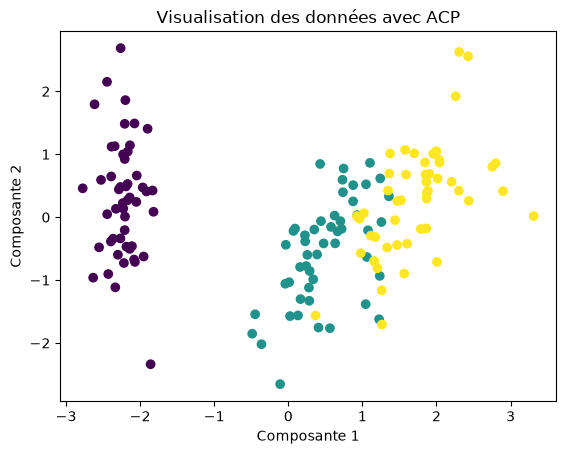

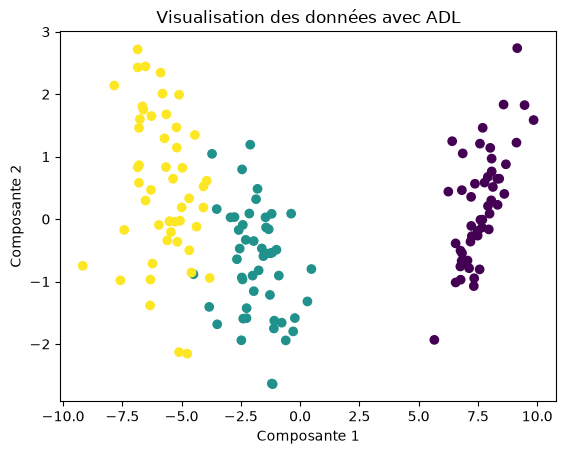

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from sklearn import *
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler 
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.cluster import KMeans, MeanShift, AffinityPropagation, SpectralClustering, DBSCAN
from sklearn.metrics import classification_report, silhouette_score, davies_bouldin_score, adjusted_mutual_info_score, adjusted_rand_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict
import warnings
warnings.filterwarnings("ignore")

iris = datasets.load_iris()

def analyse(X,Y):
    
    print("Nombre de données : ", X.shape[0])
    print("Nombre de variables : ", X.shape[1])
    print("Nombre de classes : ", len(np.unique(Y)))
    print("Moyenne ", np.mean(X, axis = 0))
    print("Écart type", np.std(X, axis = 0))
    print("min:", np.min(X, axis = 0))
    print("max:", np.max(X, axis = 0))

    scal = StandardScaler()
    X_scaled = scal.fit_transform(X)
    acp = PCA(n_components = 2)
    X_acp = acp.fit_transform(X_scaled)

    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("Visualisation des données avec ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    adl = LinearDiscriminantAnalysis(n_components = 2)
    X_adl = adl.fit_transform(X_scaled,Y)

    plt.scatter(X_adl[:,0] ,X_adl[:,1], c = Y)
    plt.title("Visualisation des données avec ADL")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()
    
analyse(iris.data,iris.target)

### Explication brève
L'ACP et l'ADL servent à réduire la dimension des données pour pouvoir faire un nuage de points en 2D.
L'ACP cherche les axes qui gardent le plus de variance possible. Elle ne va donc pas utiliser les classes mais elle n'utilise que la matrice des données X tandis que l'ADL va utiliser X et Y vu qu'elle cherche les axes qui séparent le mieux les classes.
Aussi on peut ajouter que l'ACP est une méthode d'apprentissage non supervisée alors que l'ADL est supervisée.

# B) K_means
## 1) Écriture de l'algorithme de K_means en python
L’algorithme prend en entrée la matrice des données et le nombre de clusters K, choisi par l’utilisateur. Je commence par choisir K points des données au hasard, qui servent de centres de départ. Ensuite, je répète deux étapes : j’affecte chaque point au centre le plus proche, puis je recalcule chaque centre comme la moyenne des points de son groupe. L’algorithme s’arrête quand les centres ne bougent plus, ou après un nombre maximal d’itérations. La fonction renvoie le numéro de cluster de chaque donnée.

In [2]:
def K_means(X,K):

    k_hasard = np.random.choice(len(X), size = K, replace = False)
    centres = X[k_hasard]

    compteur = 0 
    while compteur < 500 : 
        distance = metrics.pairwise.euclidean_distances(X, centres)
        
        labels = np.argmin(distance, axis = 1)
    
        bar = []
        for k in range(K):
            new_line = X[labels == k]
            if len(new_line) > 0 : 
                bar1 = new_line.mean(0)
            else : 
                bar1 = centres[k]
            bar.append(bar1)
    
        bar = np.asarray(bar)
        
        if np.allclose(bar, centres) : 
            break
        
        centres = bar
        compteur = compteur+1

    return labels

print(K_means(iris.data, 3))

cluster = KMeans(n_clusters = 3)
res = cluster.fit_predict(iris.data)
res

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 2, 2, 0, 0, 0, 0, 2, 0, 2, 0, 2, 0, 0, 2, 2, 0, 0, 0, 0,
       0, 2, 0, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 2], dtype=int32)

Les deux algorithmes séparent parfaitement setosa. Versicolor et virginica restent un peu mélangées : c'est le même chevauchement que dans l'ACP dans la partie A. 

## 2) Vérification de la variation du résultat

In [3]:
i=0
while i < 5:
    print(K_means(iris.data, 3))
    i += 1

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 2 1 1 1 1 2 1 1 1 1
 1 1 2 2 1 1 1 1 2 1 2 1 2 1 1 2 2 1 1 1 1 1 2 1 1 1 1 2 1 1 1 2 1 1 1 2 1
 1 2]
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 0 0 1 0 0 0 0
 0 0 1 1 0 0 0 0 1 0 1 0 1 0 0 1 1 0 0 0 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 1 0
 0 1]
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 

En lançant la fonction plusieurs fois, on obtient deux types de résultats. Dans certains cas, on trouve la bonne solution : les 50 premières fleurs (setosa) sont toutes dans un même cluster, et les 100 autres se partagent les deux clusters restants. Les numéros des clusters peuvent changer d’une exécution à l’autre, mais les groupes restent les mêmes.
Dans d’autres cas, on tombe sur une mauvaise solution : setosa est coupée en deux clusters, et les 100 autres fleurs sont presque toutes regroupées dans un seul cluster. Ce n’est pas une simple permutation des numéros, c’est une partition réellement différente.
Le résultat varie donc bien d’une exécution à l’autre, parce qu’il dépend des centres tirés au hasard lors de l’initialisation.

## 3) Stabilisation des résultats et sélection automatique du nombre de groupes

In [4]:
def s_score(X):
    
    best_score = -1
    best_labels = None
    best_k = 0
    
    for K in range(2,11):
        compteur = 0
        
        while compteur < 10:
            kmeans=K_means(X, K)
            score = silhouette_score(X, kmeans)
            
            if best_score <score : 
                best_score = score
                best_labels = kmeans
                best_k = K
                
            compteur += 1

    print(best_score)
    return best_labels,best_k

s_score(iris.data)

0.6810461692117462


(array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]),
 2)

### Comparaison
Ici on a 2 clusters alors que Y contient 3 classes. En effet Setosa est bien séparée alors que versicolor et virginica se chevauchent comme sur l'ACP. Les données forment donc surtout deux nuages, ce qui n'est pas anormal vu que K-means et le score silhouette ne connaissent pas les vraies classes. Ils ne voient que la forme des données.

## 4) Affichons les clusters obtenus sur l'ACP : 

Nombre de données :  150
Nombre de variables :  4
Nombre de classes :  3
Moyenne  [5.84333333 3.05733333 3.758      1.19933333]
Écart type [0.82530129 0.43441097 1.75940407 0.75969263]
min: [4.3 2.  1.  0.1]
max: [7.9 4.4 6.9 2.5]


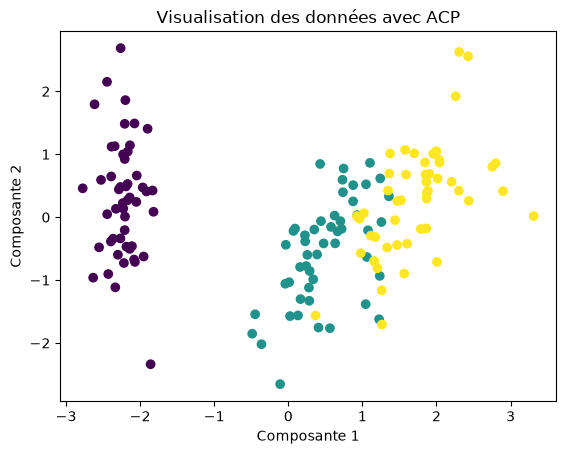

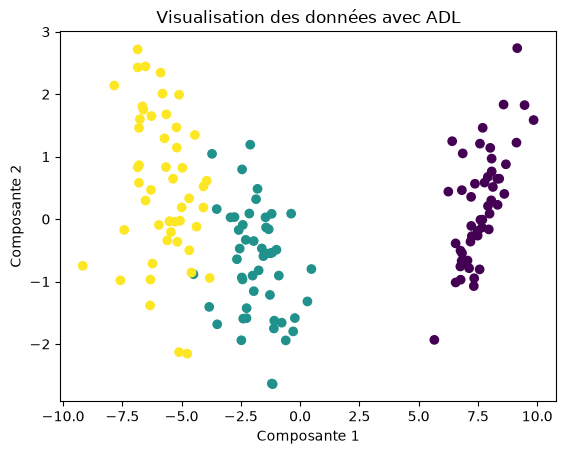

0.6810461692117462


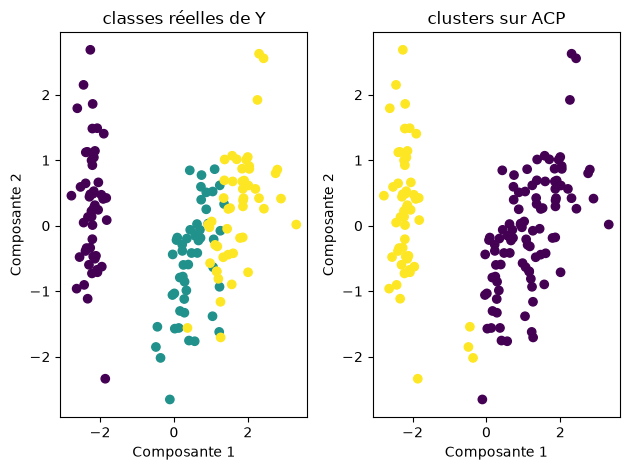

In [5]:
def analyse(X,Y):
    
    print("Nombre de données : ", X.shape[0])
    print("Nombre de variables : ", X.shape[1])
    print("Nombre de classes : ", len(np.unique(Y)))
    print("Moyenne ", np.mean(X, axis = 0))
    print("Écart type", np.std(X, axis = 0))
    print("min:", np.min(X, axis = 0))
    print("max:", np.max(X, axis = 0))

    scal = StandardScaler()
    X_scaled = scal.fit_transform(X)
    acp = PCA(n_components = 2)
    X_acp = acp.fit_transform(X_scaled)

    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("Visualisation des données avec ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    adl = LinearDiscriminantAnalysis(n_components = 2)
    X_adl = adl.fit_transform(X_scaled,Y)

    plt.scatter(X_adl[:,0] ,X_adl[:,1], c = Y)
    plt.title("Visualisation des données avec ADL")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    best_labels,best_k = s_score(X)
    plt.subplot(1,2,1)
    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("classes réelles de Y")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    
    plt.subplot(1,2,2)
    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = best_labels)
    plt.title("clusters sur ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.tight_layout()
    plt.show()

analyse(iris.data,iris.target)

### Cohérence entre les clusters et les classes de Iris
Les groupes obtenus ne sont que partiellement cohérents avec les classes. Setosa est bien retrouvée et forme son propre cluster, même si quelques points de versicolor y ont été rattachés. En revanche, versicolor et virginica sont confondues dans un seul cluster. Cela s’explique par le fait que ces deux espèces se chevauchent, comme on l’a vu sur l’ACP, et que la silhouette a retenu K = 2. De plus, K-means ne connaît pas les vraies classes : il ne voit que la forme des données.

# C) Test de différents algorithmes de clustering 
## 1) Appliquons notre fonction de la partie B et les fonctions prédéfinies pour les algorithmes de sklearn.cluster

In [6]:
def analyse(X,Y):
    
    print("Nombre de données : ", X.shape[0])
    print("Nombre de variables : ", X.shape[1])
    print("Nombre de classes : ", len(np.unique(Y)))
    print("Moyenne ", np.mean(X, axis = 0))
    print("Écart type", np.std(X, axis = 0))
    print("min:", np.min(X, axis = 0))
    print("max:", np.max(X, axis = 0))

    scal = StandardScaler()
    X_scaled = scal.fit_transform(X)
    acp = PCA(n_components = 2)
    X_acp = acp.fit_transform(X_scaled)

    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("Visualisation des données avec ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    adl = LinearDiscriminantAnalysis(n_components = 2)
    X_adl = adl.fit_transform(X_scaled,Y)

    plt.scatter(X_adl[:,0] ,X_adl[:,1], c = Y)
    plt.title("Visualisation des données avec ADL")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    best_labels,best_k = s_score(X)
    plt.subplot(1,2,1)
    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("classes réelles de Y")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    
    plt.subplot(1,2,2)
    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = best_labels)
    plt.title("clusters sur ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.tight_layout()
    plt.show()

    nb_classes = len(np.unique(Y))
    labels_km = K_means(X, nb_classes)

    ms = MeanShift()
    labels_ms = ms.fit_predict(X)

    ap = AffinityPropagation()
    labels_ap = ap.fit_predict(X)
    
    nb_clusters = nb_classes
    sc = SpectralClustering(nb_clusters)
    labels_sc = sc.fit_predict(X)

    ds = DBSCAN()
    labels_ds = ds.fit_predict(X)

    return labels_km, labels_ms, labels_sc, labels_ds

Dans la fonction analyse, j’applique cinq méthodes de clustering aux données : mon K-means de la partie B, et les fonctions Mean Shift, Affinity Propagation, Spectral Clustering et DBSCAN de sklearn.cluster. Mean Shift, Affinity Propagation et DBSCAN déterminent eux-mêmes le nombre de clusters. Pour mon K-means et pour Spectral Clustering, qui en ont besoin, j’utilise le nombre de classes de Y.

## 2-a) Calculons et affichons les scores internes de Davies-Bouldin et silhouette et les scores externes Adjusted Mutual Info et Adjusted Rand score

Nombre de données :  150
Nombre de variables :  4
Nombre de classes :  3
Moyenne  [5.84333333 3.05733333 3.758      1.19933333]
Écart type [0.82530129 0.43441097 1.75940407 0.75969263]
min: [4.3 2.  1.  0.1]
max: [7.9 4.4 6.9 2.5]


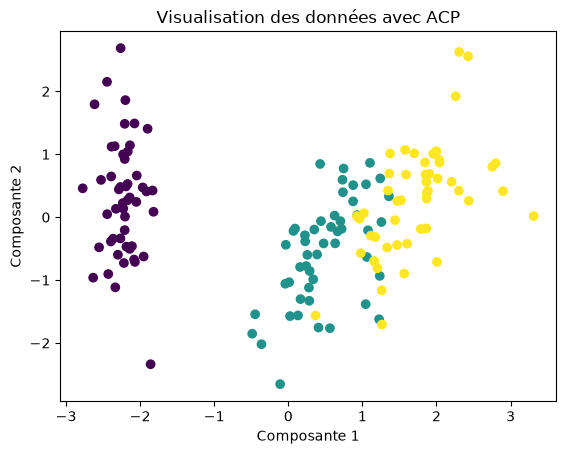

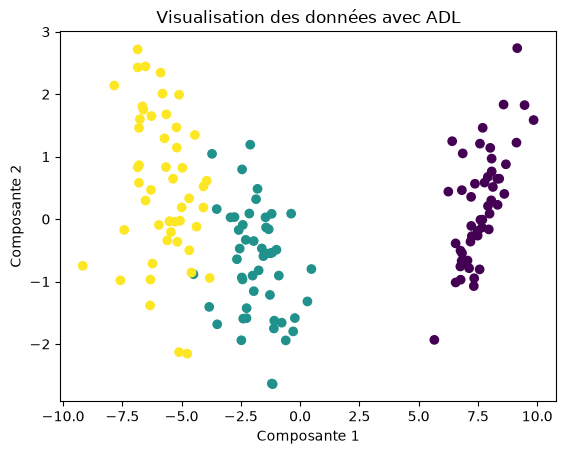

0.6810461692117462


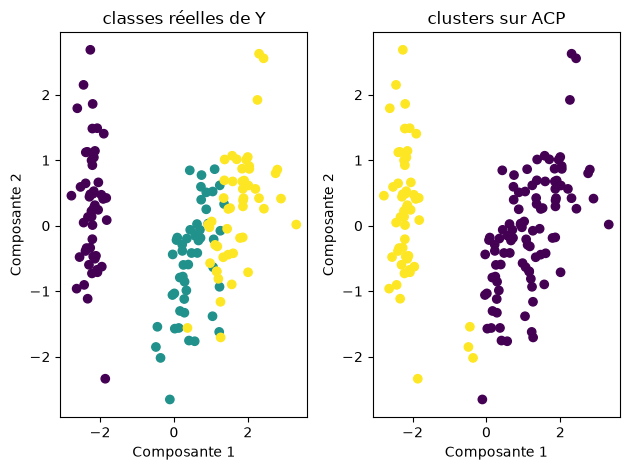

Les scores internes de Davies-Bouldin et Silhouette de la méthode Kmeans() sont respectivement :  1.0139071262459878 0.49471804251449064
Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode Kmeans() sont respectivement:  0.5831641389420004 0.41967619444922194
Les scores internes de Davies-Bouldin et Silhouette de la méthode MeanShift() sont respectivement :  0.3885516762710371 0.6857881712617192
Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode MeanShift() sont respectivement:  0.6970423665937586 0.5583714437541352
Les scores internes de Davies-Bouldin et Silhouette de la méthode AffinityPropagation() sont respectivement :  0.9853972233056495 0.347408193705561
Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode AffinityPropagation() sont respectivement:  0.6599333553254306 0.481171647498658
Les scores internes de Davies-Bouldin et Silhouette de la méthode SpectralClustering() sont respectivement :  0.6538599

In [7]:
def analyse(X,Y):
    
    print("Nombre de données : ", X.shape[0])
    print("Nombre de variables : ", X.shape[1])
    print("Nombre de classes : ", len(np.unique(Y)))
    print("Moyenne ", np.mean(X, axis = 0))
    print("Écart type", np.std(X, axis = 0))
    print("min:", np.min(X, axis = 0))
    print("max:", np.max(X, axis = 0))

    scal = StandardScaler()
    X_scaled = scal.fit_transform(X)
    acp = PCA(n_components = 2)
    X_acp = acp.fit_transform(X_scaled)

    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("Visualisation des données avec ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    adl = LinearDiscriminantAnalysis(n_components = 2)
    X_adl = adl.fit_transform(X_scaled,Y)

    plt.scatter(X_adl[:,0] ,X_adl[:,1], c = Y)
    plt.title("Visualisation des données avec ADL")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    best_labels,best_k = s_score(X)
    plt.subplot(1,2,1)
    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("classes réelles de Y")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    
    plt.subplot(1,2,2)
    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = best_labels)
    plt.title("clusters sur ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.tight_layout()
    plt.show()

    nb_classes = len(np.unique(Y))
    labels_km = K_means(X, nb_classes)
    sl_score = silhouette_score(X,labels_km)
    davb_score = davies_bouldin_score(X, labels_km)
    ami_score = adjusted_mutual_info_score(Y, labels_km)
    ar_score = adjusted_rand_score(Y, labels_km)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode Kmeans() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode Kmeans() sont respectivement: ", ami_score, ar_score)

    ms = MeanShift()
    labels_ms = ms.fit_predict(X)
    sl_score = silhouette_score(X,labels_ms)
    davb_score = davies_bouldin_score(X, labels_ms)
    ami_score = adjusted_mutual_info_score(Y, labels_ms)
    ar_score = adjusted_rand_score(Y, labels_ms)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode MeanShift() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode MeanShift() sont respectivement: ", ami_score, ar_score)
    
    ap = AffinityPropagation()
    labels_ap = ap.fit_predict(X)
    sl_score = silhouette_score(X,labels_ap)    
    davb_score = davies_bouldin_score(X, labels_ap)
    ami_score = adjusted_mutual_info_score(Y, labels_ap)
    ar_score = adjusted_rand_score(Y, labels_ap)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode AffinityPropagation() sont respectivement : ",davb_score,sl_score)    
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode AffinityPropagation() sont respectivement: ", ami_score, ar_score)
    
    sc = SpectralClustering(n_clusters = nb_classes)
    labels_sc = sc.fit_predict(X)
    sl_score = silhouette_score(X,labels_sc)
    davb_score = davies_bouldin_score(X, labels_sc)
    ami_score = adjusted_mutual_info_score(Y, labels_sc)
    ar_score = adjusted_rand_score(Y, labels_sc)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode SpectralClustering() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode SpectralClustering() sont respectivement: ", ami_score, ar_score)
    
    ds = DBSCAN()
    labels_ds = ds.fit_predict(X)
    sl_score = silhouette_score(X,labels_ds)
    davb_score = davies_bouldin_score(X, labels_ds)
    ami_score = adjusted_mutual_info_score(Y, labels_ds)
    ar_score = adjusted_rand_score(Y, labels_ds)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode DBSCAN() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode DBSCAN() sont respectivement: ", ami_score, ar_score)

analyse(iris.data, iris.target)

## 2-b) différence entre score interne et score externe
Un score interne prend en entrée la matrice des données et les labels alors qu'un score externe prend en entrée les classes de bases et les labels. En effet ce dernier compare les classes et les labels trouvés. De plus, un score interne évalue la qualité du clustering en se basant uniquement sur la structure géométrique des données sans connaître les vraies classes, il cherche souvent à maximiser la compacité des groupes et la séparation entre eux. Au contraire un score externe évalue cette qualité en comparant les groupes trouvés avec les vraies étiquettes données par un humain.

## 3) estimation à partir des résultats de la meilleure méthode de clustering 
D’après les scores internes, la meilleure méthode est Mean Shift : son score de silhouette est le plus proche de 1 (0,69) et son score de Davies-Bouldin le plus proche de 0 (0,39). Si on ne connaissait pas les vraies classes, c’est donc elle qu’on choisirait.
En revanche, d’après les scores externes, c’est Spectral Clustering qui retrouve le mieux les vraies espèces, avec l’AMI (0,80) et l’ARI (0,75) les plus proches de 1. Mon K-means la suit de près. Mean Shift a des scores externes plus faibles, car il ne trouve que 2 clusters : il fusionne versicolor et virginica, ce qui donne des groupes bien séparés géométriquement mais qui ne correspondent pas aux 3 espèces.
Affinity Propagation et DBSCAN sont les moins bonnes méthodes. Le score de Davies-Bouldin de DBSCAN (7,2) est notamment très mauvais, à cause des points considérés comme du bruit.
Comme on connaît ici les vraies classes, je retiens Spectral Clustering comme meilleure méthode de clustering.

# D) Test de différents algorithmes de classification

In [8]:
def analyse(X,Y):
    
    print("Nombre de données : ", X.shape[0])
    print("Nombre de variables : ", X.shape[1])
    print("Nombre de classes : ", len(np.unique(Y)))
    print("Moyenne ", np.mean(X, axis = 0))
    print("Écart type", np.std(X, axis = 0))
    print("min:", np.min(X, axis = 0))
    print("max:", np.max(X, axis = 0))

    scal = StandardScaler()
    X_scaled = scal.fit_transform(X)
    acp = PCA(n_components = 2)
    X_acp = acp.fit_transform(X_scaled)

    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("Visualisation des données avec ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    adl = LinearDiscriminantAnalysis(n_components = 2)
    X_adl = adl.fit_transform(X_scaled,Y)

    plt.scatter(X_adl[:,0] ,X_adl[:,1], c = Y)
    plt.title("Visualisation des données avec ADL")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    best_labels,best_k = s_score(X)
    plt.subplot(1,2,1)
    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("classes réelles de Y")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    
    plt.subplot(1,2,2)
    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = best_labels)
    plt.title("clusters sur ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.tight_layout()
    plt.show()

    nb_classes = len(np.unique(Y))
    labels_km = K_means(X, nb_classes)
    sl_score = silhouette_score(X,labels_km)
    davb_score = davies_bouldin_score(X, labels_km)
    ami_score = adjusted_mutual_info_score(Y, labels_km)
    ar_score = adjusted_rand_score(Y, labels_km)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode Kmeans() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode Kmeans() sont respectivement: ", ami_score, ar_score)

    ms = MeanShift()
    labels_ms = ms.fit_predict(X)
    sl_score = silhouette_score(X,labels_ms)
    davb_score = davies_bouldin_score(X, labels_ms)
    ami_score = adjusted_mutual_info_score(Y, labels_ms)
    ar_score = adjusted_rand_score(Y, labels_ms)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode MeanShift() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode MeanShift() sont respectivement: ", ami_score, ar_score)
    
    ap = AffinityPropagation()
    labels_ap = ap.fit_predict(X)
    sl_score = silhouette_score(X,labels_ap)    
    davb_score = davies_bouldin_score(X, labels_ap)
    ami_score = adjusted_mutual_info_score(Y, labels_ap)
    ar_score = adjusted_rand_score(Y, labels_ap)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode AffinityPropagation() sont respectivement : ",davb_score,sl_score)    
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode AffinityPropagation() sont respectivement: ", ami_score, ar_score)
    
    sc = SpectralClustering(n_clusters = nb_classes)
    labels_sc = sc.fit_predict(X)
    sl_score = silhouette_score(X,labels_sc)
    davb_score = davies_bouldin_score(X, labels_sc)
    ami_score = adjusted_mutual_info_score(Y, labels_sc)
    ar_score = adjusted_rand_score(Y, labels_sc)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode SpectralClustering() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode SpectralClustering() sont respectivement: ", ami_score, ar_score)
    
    ds = DBSCAN()
    labels_ds = ds.fit_predict(X)
    sl_score = silhouette_score(X,labels_ds)
    davb_score = davies_bouldin_score(X, labels_ds)
    ami_score = adjusted_mutual_info_score(Y, labels_ds)
    ar_score = adjusted_rand_score(Y, labels_ds)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode DBSCAN() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode DBSCAN() sont respectivement: ", ami_score, ar_score)

    knn = neighbors.KNeighborsClassifier(n_neighbors = 1)
    pred_knn = cross_val_predict(knn, X, Y, cv = LeaveOneOut())

    gbn = naive_bayes.GaussianNB()
    pred_gbn = cross_val_predict(gbn, X, Y, cv =  LeaveOneOut())

    mlp = neural_network.MLPClassifier()
    pred_mlp = cross_val_predict(mlp, X, Y, cv = LeaveOneOut())

    svc = svm.SVC()
    pred_svc = cross_val_predict(svc, X, Y, cv = LeaveOneOut())

## 2) Pour chaque méthode, calculons et affichons le pourcentage d’erreurs, puis les valeurs de precision, recall et f1-score pour chaque classe (fonction classification_report) 

Nombre de données :  150
Nombre de variables :  4
Nombre de classes :  3
Moyenne  [5.84333333 3.05733333 3.758      1.19933333]
Écart type [0.82530129 0.43441097 1.75940407 0.75969263]
min: [4.3 2.  1.  0.1]
max: [7.9 4.4 6.9 2.5]


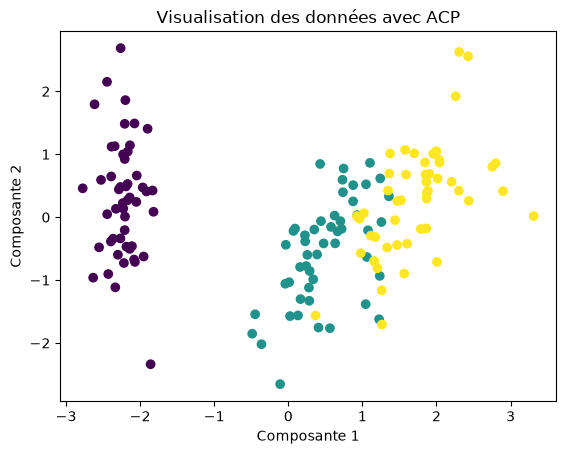

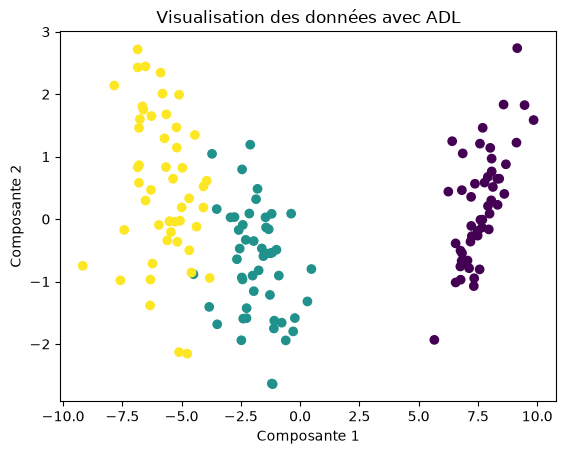

0.6810461692117462


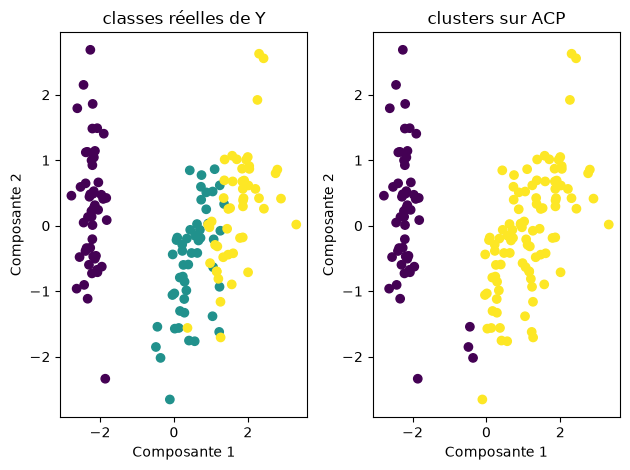

Les scores internes de Davies-Bouldin et Silhouette de la méthode Kmeans() sont respectivement :  0.6660385791628517 0.5511916046195919
Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode Kmeans() sont respectivement:  0.7386548254402865 0.7163421126838476
Les scores internes de Davies-Bouldin et Silhouette de la méthode MeanShift() sont respectivement :  0.3885516762710371 0.6857881712617192
Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode MeanShift() sont respectivement:  0.6970423665937586 0.5583714437541352
Les scores internes de Davies-Bouldin et Silhouette de la méthode AffinityPropagation() sont respectivement :  0.9853972233056495 0.347408193705561
Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode AffinityPropagation() sont respectivement:  0.6599333553254306 0.481171647498658
Les scores internes de Davies-Bouldin et Silhouette de la méthode SpectralClustering() sont respectivement :  0.653859926

In [9]:
def analyse(X,Y):
    
    print("Nombre de données : ", X.shape[0])
    print("Nombre de variables : ", X.shape[1])
    print("Nombre de classes : ", len(np.unique(Y)))
    print("Moyenne ", np.mean(X, axis = 0))
    print("Écart type", np.std(X, axis = 0))
    print("min:", np.min(X, axis = 0))
    print("max:", np.max(X, axis = 0))

    scal = StandardScaler()
    X_scaled = scal.fit_transform(X)
    acp = PCA(n_components = 2)
    X_acp = acp.fit_transform(X_scaled)

    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("Visualisation des données avec ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    adl = LinearDiscriminantAnalysis(n_components = 2)
    X_adl = adl.fit_transform(X_scaled,Y)

    plt.scatter(X_adl[:,0] ,X_adl[:,1], c = Y)
    plt.title("Visualisation des données avec ADL")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    best_labels,best_k = s_score(X)
    plt.subplot(1,2,1)
    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("classes réelles de Y")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    
    plt.subplot(1,2,2)
    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = best_labels)
    plt.title("clusters sur ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.tight_layout()
    plt.show()

    nb_classes = len(np.unique(Y))
    labels_km = K_means(X, nb_classes)
    sl_score = silhouette_score(X,labels_km)
    davb_score = davies_bouldin_score(X, labels_km)
    ami_score = adjusted_mutual_info_score(Y, labels_km)
    ar_score = adjusted_rand_score(Y, labels_km)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode Kmeans() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode Kmeans() sont respectivement: ", ami_score, ar_score)

    ms = MeanShift()
    labels_ms = ms.fit_predict(X)
    sl_score = silhouette_score(X,labels_ms)
    davb_score = davies_bouldin_score(X, labels_ms)
    ami_score = adjusted_mutual_info_score(Y, labels_ms)
    ar_score = adjusted_rand_score(Y, labels_ms)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode MeanShift() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode MeanShift() sont respectivement: ", ami_score, ar_score)
    
    ap = AffinityPropagation()
    labels_ap = ap.fit_predict(X)
    sl_score = silhouette_score(X,labels_ap)    
    davb_score = davies_bouldin_score(X, labels_ap)
    ami_score = adjusted_mutual_info_score(Y, labels_ap)
    ar_score = adjusted_rand_score(Y, labels_ap)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode AffinityPropagation() sont respectivement : ",davb_score,sl_score)    
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode AffinityPropagation() sont respectivement: ", ami_score, ar_score)
    
    sc = SpectralClustering(n_clusters = nb_classes)
    labels_sc = sc.fit_predict(X)
    sl_score = silhouette_score(X,labels_sc)
    davb_score = davies_bouldin_score(X, labels_sc)
    ami_score = adjusted_mutual_info_score(Y, labels_sc)
    ar_score = adjusted_rand_score(Y, labels_sc)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode SpectralClustering() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode SpectralClustering() sont respectivement: ", ami_score, ar_score)
    
    ds = DBSCAN()
    labels_ds = ds.fit_predict(X)
    sl_score = silhouette_score(X,labels_ds)
    davb_score = davies_bouldin_score(X, labels_ds)
    ami_score = adjusted_mutual_info_score(Y, labels_ds)
    ar_score = adjusted_rand_score(Y, labels_ds)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode DBSCAN() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode DBSCAN() sont respectivement: ", ami_score, ar_score)

    knn = neighbors.KNeighborsClassifier(n_neighbors = 1)
    pred_knn = cross_val_predict(knn, X, Y, cv = LeaveOneOut())
    err_knn = ((pred_knn != Y).mean())*100
    print("Le pourcentage d'erreurs du PPV est :", err_knn)
    print("La précision, le recall, le f1-score du PPV sont :\n" , classification_report(Y, pred_knn))

    gbn = naive_bayes.GaussianNB()
    pred_gbn = cross_val_predict(gbn, X, Y, cv =  LeaveOneOut())
    err_gbn = ((pred_gbn != Y).mean())*100
    print("Le pourcentage d'erreurs du CBN est :", err_gbn)
    print("La précision, le recall, le f1-score du CBN sont :\n" , classification_report(Y, pred_gbn))
    
    mlp = neural_network.MLPClassifier()
    pred_mlp = cross_val_predict(mlp, X, Y, cv = LeaveOneOut())
    err_mlp = ((pred_mlp != Y).mean())*100
    print("Le pourcentage d'erreurs du MLP est :", err_mlp)
    print("La précision, le recall, le f1-score du MLP sont :\n" , classification_report(Y, pred_mlp))

    svc = svm.SVC()
    pred_svc = cross_val_predict(svc, X, Y, cv = LeaveOneOut())
    err_svc = ((pred_svc != Y).mean())*100
    print("Le pourcentage d'erreurs du SVC est :", err_svc)
    print("La précision, le recall, le f1-score du SVC sont :\n" , classification_report(Y, pred_svc))

analyse(iris.data, iris.target)

## 3) Estimation de la meilleure méthode de classification
Sur les données Iris, les quatre méthodes donnent de très bons résultats. Le MLP obtient le plus faible pourcentage d’erreurs (2,67 %, soit 4 erreurs sur 150), suivi du SVC (3,33 %, soit 5 erreurs), du Plus Proche Voisin (4 %, soit 6 erreurs) et du Classifieur Bayésien Naïf (4,67 %, soit 7 erreurs). Les écarts sont donc très faibles.
Le classification_report montre que toutes les méthodes classent parfaitement setosa (précision, recall et f1-score de 1,00). Les erreurs se situent toutes entre versicolor et virginica, deux espèces qui se chevauchent, comme on l’a vu sur l’ACP.
Le résultat du MLP varie d’une exécution à l’autre. Sur 4 exécutions, il a obtenu soit 2,67 %, soit 3,33 % d’erreurs, c’est-à-dire toujours un résultat égal ou meilleur que celui des autres méthodes. Je retiens donc le MLP comme meilleure méthode de classification, le SVC étant une alternative presque aussi performante et plus stable.

# E) Utilisation de la fonction
## 1) Résultats sur les données Iris
Les données contiennent 150 fleurs décrites par 4 variables, réparties en 3 espèces. Sur l’ACP comme sur l’ADL, setosa est nettement séparée des deux autres espèces, alors que versicolor et virginica se chevauchent en partie. L’ADL les sépare un peu mieux, car elle utilise les classes.
En clustering, la silhouette retient 2 clusters seulement, car versicolor et virginica forment un seul nuage. Mean Shift obtient les meilleurs scores internes, mais Spectral Clustering retrouve le mieux les vraies espèces (meilleurs AMI et ARI).
En classification, toutes les méthodes obtiennent moins de 5 % d’erreurs. Setosa est toujours parfaitement classée, et les erreurs se concentrent entre versicolor et virginica. Le MLP obtient le meilleur résultat.
Ces données sont donc faciles à classer avec un apprentissage supervisé, mais plus difficiles à regrouper correctement sans connaître les classes, à cause du chevauchement entre versicolor et virginica.

## 2) Importation et analyse des données wine :

Nombre de données :  178
Nombre de variables :  13
Nombre de classes :  3
Moyenne  [1.30006180e+01 2.33634831e+00 2.36651685e+00 1.94949438e+01
 9.97415730e+01 2.29511236e+00 2.02926966e+00 3.61853933e-01
 1.59089888e+00 5.05808988e+00 9.57449438e-01 2.61168539e+00
 7.46893258e+02]
Écart type [8.09542915e-01 1.11400363e+00 2.73572294e-01 3.33016976e+00
 1.42423077e+01 6.24090564e-01 9.96048950e-01 1.24103260e-01
 5.70748849e-01 2.31176466e+00 2.27928607e-01 7.07993265e-01
 3.14021657e+02]
min: [1.103e+01 7.400e-01 1.360e+00 1.060e+01 7.000e+01 9.800e-01 3.400e-01
 1.300e-01 4.100e-01 1.280e+00 4.800e-01 1.270e+00 2.780e+02]
max: [1.483e+01 5.800e+00 3.230e+00 3.000e+01 1.620e+02 3.880e+00 5.080e+00
 6.600e-01 3.580e+00 1.300e+01 1.710e+00 4.000e+00 1.680e+03]


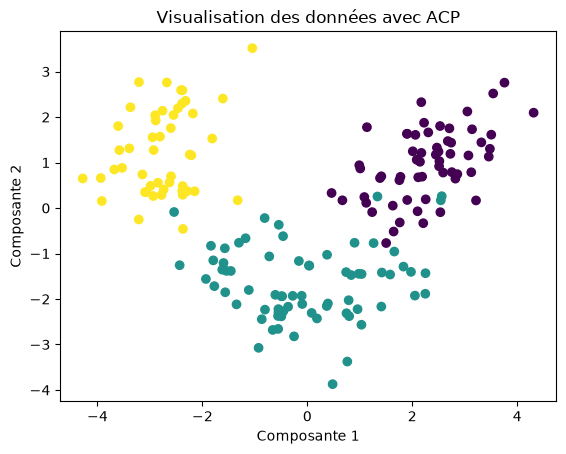

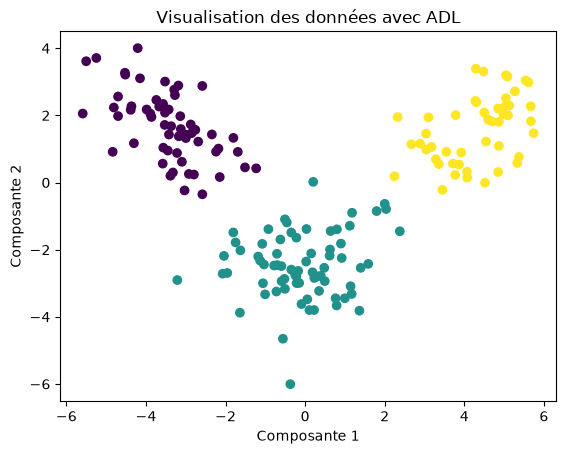

0.6568536504294317


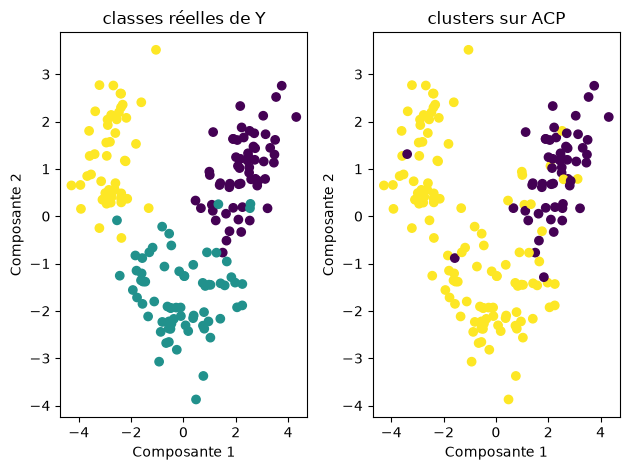

Les scores internes de Davies-Bouldin et Silhouette de la méthode Kmeans() sont respectivement :  0.5342431775436278 0.5711381937868838
Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode Kmeans() sont respectivement:  0.42268666427661195 0.37111371823084754
Les scores internes de Davies-Bouldin et Silhouette de la méthode MeanShift() sont respectivement :  0.5561495856687307 0.5024921259394886
Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode MeanShift() sont respectivement:  0.45488977083017085 0.39723664098601413
Les scores internes de Davies-Bouldin et Silhouette de la méthode AffinityPropagation() sont respectivement :  0.49940780406287844 0.5351781288233152
Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode AffinityPropagation() sont respectivement:  0.33154469129400427 0.19051151696510224
Les scores internes de Davies-Bouldin et Silhouette de la méthode SpectralClustering() sont respectivement :  0.

In [10]:
wine = datasets.load_wine()
def analyse(X,Y):
    
    print("Nombre de données : ", X.shape[0])
    print("Nombre de variables : ", X.shape[1])
    print("Nombre de classes : ", len(np.unique(Y)))
    print("Moyenne ", np.mean(X, axis = 0))
    print("Écart type", np.std(X, axis = 0))
    print("min:", np.min(X, axis = 0))
    print("max:", np.max(X, axis = 0))

    scal = StandardScaler()
    X_scaled = scal.fit_transform(X)
    acp = PCA(n_components = 2)
    X_acp = acp.fit_transform(X_scaled)

    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("Visualisation des données avec ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    adl = LinearDiscriminantAnalysis(n_components = 2)
    X_adl = adl.fit_transform(X_scaled,Y)

    plt.scatter(X_adl[:,0] ,X_adl[:,1], c = Y)
    plt.title("Visualisation des données avec ADL")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.show()

    best_labels,best_k = s_score(X)
    plt.subplot(1,2,1)
    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = Y)
    plt.title("classes réelles de Y")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    
    plt.subplot(1,2,2)
    plt.scatter(X_acp[:,0] ,X_acp[:,1], c = best_labels)
    plt.title("clusters sur ACP")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.tight_layout()
    plt.show()

    nb_classes = len(np.unique(Y))
    labels_km = K_means(X, nb_classes)
    sl_score = silhouette_score(X,labels_km)
    davb_score = davies_bouldin_score(X, labels_km)
    ami_score = adjusted_mutual_info_score(Y, labels_km)
    ar_score = adjusted_rand_score(Y, labels_km)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode Kmeans() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode Kmeans() sont respectivement: ", ami_score, ar_score)

    ms = MeanShift()
    labels_ms = ms.fit_predict(X)
    sl_score = silhouette_score(X,labels_ms)
    davb_score = davies_bouldin_score(X, labels_ms)
    ami_score = adjusted_mutual_info_score(Y, labels_ms)
    ar_score = adjusted_rand_score(Y, labels_ms)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode MeanShift() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode MeanShift() sont respectivement: ", ami_score, ar_score)
    
    ap = AffinityPropagation()
    labels_ap = ap.fit_predict(X)
    sl_score = silhouette_score(X,labels_ap)    
    davb_score = davies_bouldin_score(X, labels_ap)
    ami_score = adjusted_mutual_info_score(Y, labels_ap)
    ar_score = adjusted_rand_score(Y, labels_ap)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode AffinityPropagation() sont respectivement : ",davb_score,sl_score)    
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode AffinityPropagation() sont respectivement: ", ami_score, ar_score)
    
    sc = SpectralClustering(n_clusters = nb_classes)
    labels_sc = sc.fit_predict(X)
    sl_score = silhouette_score(X,labels_sc)
    davb_score = davies_bouldin_score(X, labels_sc)
    ami_score = adjusted_mutual_info_score(Y, labels_sc)
    ar_score = adjusted_rand_score(Y, labels_sc)
    print("Les scores internes de Davies-Bouldin et Silhouette de la méthode SpectralClustering() sont respectivement : ",davb_score,sl_score)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode SpectralClustering() sont respectivement: ", ami_score, ar_score)
    
    ds = DBSCAN()
    labels_ds = ds.fit_predict(X)
    if len(np.unique(labels_ds)) >= 2 :
        sl_score = silhouette_score(X,labels_ds)
        davb_score = davies_bouldin_score(X, labels_ds)
        print("Les scores internes de Davies-Bouldin et Silhouette de la méthode DBSCAN() sont respectivement : ",davb_score,sl_score)
    else : 
        print("DBSCAN n'a trouvé qu'un seul cluster,score interne non calculables.")
    ami_score = adjusted_mutual_info_score(Y, labels_ds)
    ar_score = adjusted_rand_score(Y, labels_ds)
    print("Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode DBSCAN() sont respectivement: ", ami_score, ar_score)

    knn = neighbors.KNeighborsClassifier(n_neighbors = 1)
    pred_knn = cross_val_predict(knn, X, Y, cv = LeaveOneOut())
    err_knn = ((pred_knn != Y).mean())*100
    print("Le pourcentage d'erreurs du PPV est :", err_knn)
    print("La précision, le recall, le f1-score du PPV sont :\n" , classification_report(Y, pred_knn))

    gbn = naive_bayes.GaussianNB()
    pred_gbn = cross_val_predict(gbn, X, Y, cv =  LeaveOneOut())
    err_gbn = ((pred_gbn != Y).mean())*100
    print("Le pourcentage d'erreurs du CBN est :", err_gbn)
    print("La précision, le recall, le f1-score du CBN sont :\n" , classification_report(Y, pred_gbn))
    
    mlp = neural_network.MLPClassifier()
    pred_mlp = cross_val_predict(mlp, X, Y, cv = LeaveOneOut())
    err_mlp = ((pred_mlp != Y).mean())*100
    print("Le pourcentage d'erreurs du MLP est :", err_mlp)
    print("La précision, le recall, le f1-score du MLP sont :\n" , classification_report(Y, pred_mlp))

    svc = svm.SVC()
    pred_svc = cross_val_predict(svc, X, Y, cv = LeaveOneOut())
    err_svc = ((pred_svc != Y).mean())*100
    print("Le pourcentage d'erreurs du SVC est :", err_svc)
    print("La précision, le recall, le f1-score du SVC sont :\n" , classification_report(Y, pred_svc))

analyse(wine.data, wine.target)

Le jeu de données Wine contient 178 vins provenant de 3 lieux différents. Il compte 13 variables, qui correspondent aux quantités mesurées de 13 constituants chimiques présents dans les vins.
L’ACP montre 3 classes plutôt distinctes, même si certains vins de la classe 1 se mélangent avec les classes 0 et 2. L’ADL, qui utilise les classes, sépare les 3 classes très nettement.
Les 13 variables n’ont pas du tout la même échelle : certaines ont des valeurs de plusieurs centaines, alors que d’autres sont proches de 1. Comme le clustering et la plupart des classifieurs reposent sur des distances, ces variables à grande échelle écrasent les autres.
En clustering, les résultats sont donc médiocres. D’après les scores internes, la meilleure méthode est mon K-means, et d’après les scores externes, c’est Mean Shift. DBSCAN ne trouve qu’un seul cluster avec ses paramètres par défaut, donc ses scores internes ne peuvent pas être calculés.
En classification, le Classifieur Bayésien Naïf est clairement le meilleur, avec seulement 2,25 % d’erreurs, un écart très net avec les autres méthodes. Cela s’explique par le fait qu’il traite chaque variable séparément, avec sa propre moyenne et son propre écart type : la différence d’échelle ne le gêne donc pas. Le Plus Proche Voisin, le SVC et le MLP, qui utilisent des distances ou des combinaisons de variables, sont au contraire pénalisés.

## 3) Centrage et réduction

Nombre de données :  178
Nombre de variables :  13
Nombre de classes :  3
Moyenne  [ 7.84141790e-15  2.44498554e-16 -4.05917497e-15 -7.11041712e-17
 -2.49488320e-17 -1.95536471e-16  9.44313292e-16 -4.17892936e-16
 -1.54059038e-15 -4.12903170e-16  1.39838203e-15  2.12688793e-15
 -6.98567296e-17]
Écart type [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
min: [-2.43423535 -1.43298305 -3.67916223 -2.67101814 -2.0882552  -2.10724602
 -1.69597053 -1.86823402 -2.06903418 -1.63428828 -2.09473241 -1.89505389
 -1.49318765]
max: [2.25977152 3.10919247 3.15632527 3.15451071 4.37137214 2.53951547
 3.06283174 2.40240319 3.48507251 3.43543192 3.30169422 1.96091499
 2.97147258]


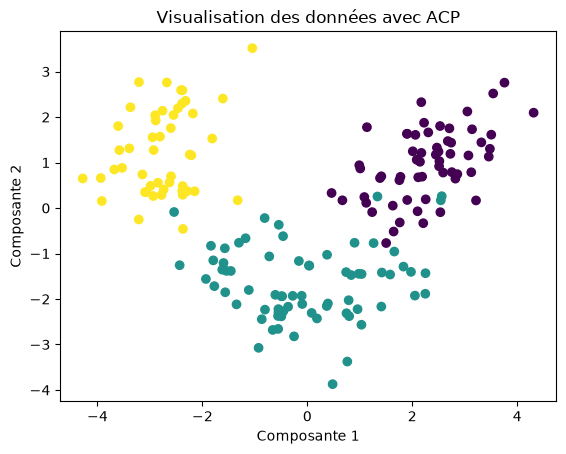

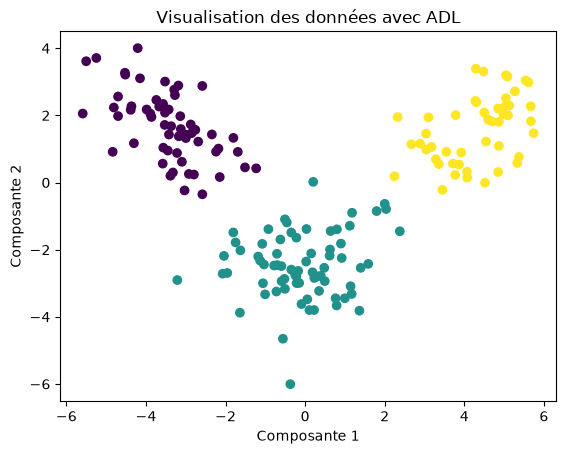

0.2922545313424156


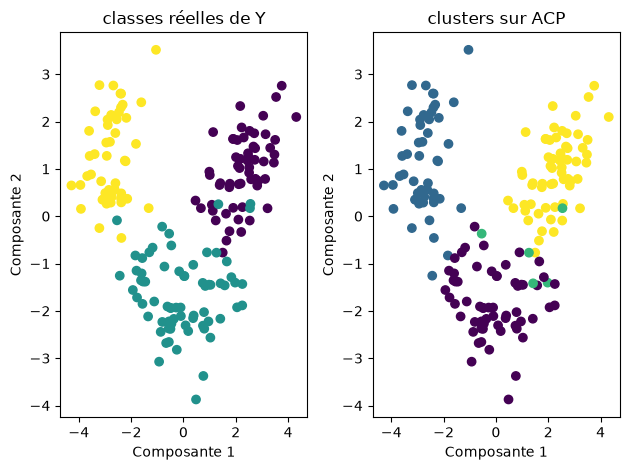

Les scores internes de Davies-Bouldin et Silhouette de la méthode Kmeans() sont respectivement :  1.3891879777181646 0.2848589191898987
Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode Kmeans() sont respectivement:  0.874579440437926 0.8974949815093207
Les scores internes de Davies-Bouldin et Silhouette de la méthode MeanShift() sont respectivement :  1.3200588029456868 0.22447619269259034
Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode MeanShift() sont respectivement:  0.023679396539395863 -0.0064242403723043275
Les scores internes de Davies-Bouldin et Silhouette de la méthode AffinityPropagation() sont respectivement :  1.6661747518072072 0.12094943296335095
Les scores externes Adjusted Mutual Info et Adjusted Rand score de la méthode AffinityPropagation() sont respectivement:  0.5043982814291912 0.2728590642231466
Les scores internes de Davies-Bouldin et Silhouette de la méthode SpectralClustering() sont respectivement :  1.

In [11]:
scal = StandardScaler()
wine_scaled = scal.fit_transform(wine.data)
analyse(wine_scaled, wine.target)

Après standardisation, toutes les variables ont la même échelle et pèsent autant dans les calculs de distance.
Pour le clustering, les scores externes s’améliorent nettement. Mon K-means retrouve très bien les trois types de vins, avec un AMI et un ARI d’environ 0,85. Spectral Clustering et Affinity Propagation donnent des résultats moyens (ARI de 0,44 et 0,27). DBSCAN ne trouve qu’un seul groupe et a des scores externes proches de 0. Les scores internes restent faibles (silhouette entre 0,12 et 0,28), mais ils ne sont pas directement comparables à ceux de E2 : la standardisation change les distances, et les 13 variables comptent désormais toutes, ce qui rend les groupes moins compacts géométriquement. Les scores externes montrent bien que le regroupement correspond beaucoup mieux aux vraies classes.
Pour la classification, les méthodes basées sur des distances ou des combinaisons de variables s’améliorent fortement. Le SVC et le MLP passent à 1,69 % d’erreurs, et le Plus Proche Voisin à 4,49 %. Le Classifieur Bayésien Naïf reste à 2,25 %, exactement comme sur les données brutes, ce qui confirme qu’il n’est pas sensible à l’échelle des variables. Le SVC et le MLP deviennent donc les meilleures méthodes.
Standardiser les données est donc indispensable lorsque les variables n’ont pas la même échelle, aussi bien pour le clustering que pour la classification.